In [1]:
import pandas as pd
import os

In [2]:
try:
    from IGTD_Functions import table_to_image, min_max_transform
except ImportError:
    print("Error: It seems 'IGTD_Functions.py' could not be imported.")
    print("Please check that the file is in the same directory as this notebook,")
    print("or that it's accessible in your Python path.")
    raise ImportError("Could not find IGTD_Functions.py. Please check the location.")

In [3]:
# --- Configuration Settings ---
DATASET_FILE_PATH = "../Datasets/excel/GPS_Data_Simplified_2D_Feature_Map.xlsx"
OUTPUT_TARGET_COLUMN = 'Output'

# Image layout and feature comparison methods
IMAGE_SCALE_ROWS = 4
IMAGE_SCALE_COLS = 4
FEATURE_DISTANCE_METHOD = 'Euclidean' # choices: 'Euclidean', 'Pearson', 'Spearman'
PIXEL_DISTANCE_METHOD = 'Euclidean' # choices: 'Euclidean', 'Manhattan'

# settings for IGTD
ERROR_METRIC = 'abs' # How to measure error: 'abs' or 'squared'
MAX_ITERATION_STEPS = 10000  # How many attempts to optimize the layout.
VALIDATION_STEPS = 300       # Check for improvement every so many steps.
SWITCH_THRESHOLD = 0           # How much better a swap needs to be (0 means any improvement).
MIN_IMPROVEMENT_GAIN = 0.000001 # The smallest improvement that counts as progress.

# Where to save results
RESULTS_OUTPUT_DIRECTORY = "IGTD_GPS_Results"
SAVE_IMAGE_SIZE_INCHES = 5   # For any saved plot images.
proceed_with_script = True

In [4]:
print(f"\nTrying to load the dataset from: {DATASET_FILE_PATH}")
data = None
try:
    data = pd.read_excel(
        DATASET_FILE_PATH,
        na_values=['na', '-', ''],
        header=0,
        index_col=0,
    )
    print(f"Dataset loaded successfully. It has {data.shape[0]} rows and {data.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The file '{DATASET_FILE_PATH}' wasn't found. Please check the path.")
    proceed_with_script = False
except Exception as e:
    print(f"An unexpected error occurred while loading the dataset: {e}")
    proceed_with_script = False

if data is None and proceed_with_script:
    print("Error: Data could not be loaded (the DataFrame is empty).")
    proceed_with_script = False


Trying to load the dataset from: ../Datasets/excel/GPS_Data_Simplified_2D_Feature_Map.xlsx
Dataset loaded successfully. It has 510530 rows and 13 columns.


In [5]:
features_df = None
if proceed_with_script:
    try:
        if OUTPUT_TARGET_COLUMN and OUTPUT_TARGET_COLUMN in data.columns:
            features_df = data.drop(columns=[OUTPUT_TARGET_COLUMN])
            print(f"The '{OUTPUT_TARGET_COLUMN}' column has been excluded. The rest will be used as features.")
        else:
            features_df = data.copy()
            if OUTPUT_TARGET_COLUMN:
                print(f"Note: The column '{OUTPUT_TARGET_COLUMN}' wasn't found. All columns will be used as features.")
            else:
                print("All columns from the dataset will be used as features.")
        
        if features_df.empty or features_df.shape[1] == 0:
            print("Error: After preparing the data, there are no features left to process.")
            proceed_with_script = False
        else:
            print(f"There are {features_df.shape[1]} features ready for IGTD.")
    except Exception as e:
        print(f"An error occurred while preparing the data: {e}")
        proceed_with_script = False

The 'Output' column has been excluded. The rest will be used as features.
There are 12 features ready for IGTD.


In [6]:
features_normalized_df = None
if proceed_with_script:
    print("\nNormalizing features to a 0-1 scale using min-max transformation...")
    try:
        features_normalized_values = min_max_transform(features_df.astype(float).copy().values)
        features_normalized_df = pd.DataFrame(features_normalized_values,
                                              columns=features_df.columns,
                                              index=features_df.index)
        print("Feature normalization is complete.")
    except Exception as e:
        print(f"An error occurred during feature normalization: {e}")
        proceed_with_script = False
    
    if features_normalized_df is None and proceed_with_script:
        print("Error: Normalization step did not produce a result.")
        proceed_with_script = False


Normalizing features to a 0-1 scale using min-max transformation...
Feature normalization is complete.


In [7]:
output_dir_ready = False
if proceed_with_script:
    print(f"\nSetting up the output directory: {RESULTS_OUTPUT_DIRECTORY}")
    try:
        if not os.path.exists(RESULTS_OUTPUT_DIRECTORY):
            os.makedirs(RESULTS_OUTPUT_DIRECTORY)
            print(f"Output directory created at: {RESULTS_OUTPUT_DIRECTORY}")
        else:
            print(f"Output directory '{RESULTS_OUTPUT_DIRECTORY}' already exists. Files may be overwritten.")
        output_dir_ready = True
    except OSError as e:
        print(f"Error creating the output directory '{RESULTS_OUTPUT_DIRECTORY}': {e}")
        proceed_with_script = False
    except Exception as e:
        print(f"An unexpected error occurred with the output directory: {e}")
        proceed_with_script = False


Setting up the output directory: IGTD_GPS_Results
Output directory created at: IGTD_GPS_Results



All checks passed. This might take some time...
  Image Dimensions: 4x4 pixels
  Feature Distance Method: Euclidean
  Results will be saved in: 'IGTD_GPS_Results'
Step 0 err: 1084.0
Step 1 err: 1084.0
Step 2 err: 1008.0
Step 3 err: 1008.0
Step 4 err: 980.0
Step 5 err: 980.0
Step 6 err: 928.0
Step 7 err: 918.0
Step 8 err: 918.0
Step 9 err: 918.0
Step 10 err: 918.0
Step 11 err: 918.0
Step 12 err: 918.0
Step 13 err: 918.0
Step 14 err: 918.0
Step 15 err: 918.0
Step 16 err: 908.0
Step 17 err: 908.0
Step 18 err: 908.0
Step 19 err: 908.0
Step 20 err: 908.0
Step 21 err: 880.0
Step 22 err: 880.0
Step 23 err: 880.0
Step 24 err: 880.0
Step 25 err: 880.0
Step 26 err: 880.0
Step 27 err: 880.0
Step 28 err: 880.0
Step 29 err: 880.0
Step 30 err: 880.0
Step 31 err: 880.0
Step 32 err: 880.0
Step 33 err: 880.0
Step 34 err: 880.0
Step 35 err: 880.0
Step 36 err: 880.0
Step 37 err: 880.0
Step 38 err: 880.0
Step 39 err: 880.0
Step 40 err: 880.0
Step 41 err: 880.0
Step 42 err: 880.0
Step 43 err: 880.0
Step 4

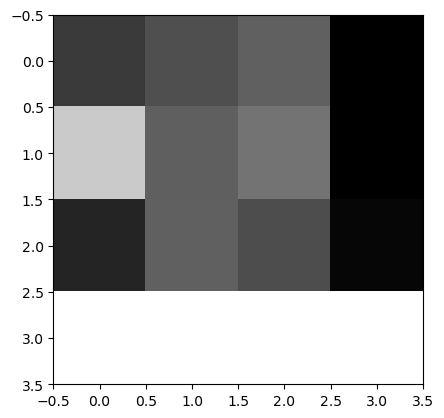

In [8]:
if proceed_with_script:
    print("\nAll checks passed. This might take some time...")
    image_dimensions = [IMAGE_SCALE_ROWS, IMAGE_SCALE_COLS]
    print(f"  Image Dimensions: {image_dimensions[0]}x{image_dimensions[1]} pixels")
    print(f"  Feature Distance Method: {FEATURE_DISTANCE_METHOD}")
    print(f"  Results will be saved in: '{RESULTS_OUTPUT_DIRECTORY}'")
    try:
        table_to_image(
            norm_d=features_normalized_df,
            scale=image_dimensions,
            fea_dist_method=FEATURE_DISTANCE_METHOD,
            image_dist_method=PIXEL_DISTANCE_METHOD,
            save_image_size=SAVE_IMAGE_SIZE_INCHES,
            max_step=MAX_ITERATION_STEPS,
            val_step=VALIDATION_STEPS,
            normDir=RESULTS_OUTPUT_DIRECTORY,
            error=ERROR_METRIC,
            switch_t=SWITCH_THRESHOLD,
            min_gain=MIN_IMPROVEMENT_GAIN
        )
        print("\nIGTD processing has finished.")
        print(f" Find the results in the '{RESULTS_OUTPUT_DIRECTORY}' folder.")
    except Exception as e:
        print(f"\nAn error occurred while running the IGTD algorithm: {e}")
else:
    print("\nScript did not complete due to earlier errors. Please review the messages above.")